In [327]:
import numpy as np
import pandas as pd
import librosa
import librosa.display
import jams
import json
from pathlib import Path
from pprint import pprint
import math
from fractions import Fraction
from IPython.display import Audio

import matplotlib.pyplot as plt

In [29]:
dataset_dir = Path.cwd().parent.joinpath( "data/guitarset")
annotation_dir = dataset_dir / "annotation"
audio_dir = dataset_dir / "audio_mono-mic_comp"
take_id = "00_BN1-129-Eb_comp"
annotation_filename = take_id+".jams"
audio_filename = take_id+"_mic.wav"
anno_file = dataset_dir / annotation_dir / annotation_filename
audio_file = dataset_dir / audio_dir / audio_filename

anno_jams = jams.load(str(anno_file))

In [343]:
def retrieve_anno_namespace(jams_file, description):
    lst = []
    for anno in jams_file["annotations"]:
        if anno["namespace"] == description:
            lst.append(anno)
    return lst

def convert_lead_chord_anno(chord_obj: jams.Annotation):
    print(type(chord_obj))
    k = len(chord_obj["data"])
    ref_intervals = np.empty((k,2))
    ref_labels = []
    for idx, obs in enumerate(chord_obj["data"]):
        ref_intervals[int(idx)] = [obs.time, obs.time+obs.duration]
        ref_labels.append(obs.value)

    return ref_intervals, ref_labels

chords_obj = retrieve_anno_namespace(anno_jams, "chord")
ref_intervals, ref_labels = convert_lead_chord_anno(chords_obj[0])
ref_combined = np.concat([ref_intervals, np.array(ref_labels).reshape(-1,1)], axis=1)
print(ref_intervals)

<class 'jams.core.Annotation'>
[[ 0.          7.44186047]
 [ 7.44186047 11.1627907 ]
 [11.1627907  14.88372093]
 [14.88372093 16.74418605]
 [16.74418605 18.60465116]
 [18.60465116 22.3244    ]]


In [220]:
ref_labels

['D#:maj', 'G#:maj', 'D#:maj', 'A#:maj', 'G#:maj', 'D#:maj']

In [221]:
# Load the audio
audio_array, sr = librosa.load(audio_file, sr=22050, mono=True)
duration = len(audio_array)/sr
assert math.isclose(anno_jams["file_metadata"]["duration"], duration, rel_tol=5e-2)
print(f"File calculated duration: {duration:.4f} seconds")
print(f"File metadata duration: {anno_jams['file_metadata']['duration']:.4f} seconds")

# Verify intervals starts at 0
assert ref_intervals[0,0]==0.0
# Inspect chord length in beats - BPM in the filename is 129
bpm = 129
print(f"Chord length in beats: {(ref_intervals[:, 1] - ref_intervals[:, 0]) * bpm / 60}")

File calculated duration: 22.3244 seconds
File metadata duration: 22.3244 seconds
Chord length in beats: [16.       8.       8.       4.       4.       7.99746]


In [222]:
Audio(audio_array, rate=sr)

In [304]:
audio_harmo = librosa.effects.harmonic(audio_array, margin=4)
chroma = librosa.feature.chroma_cqt(y=audio_harmo, sr=sr, hop_length=512, threshold=0.25)

# Create templates for major, minor, and no-chord qualities
maj_template = np.array([1,0,0, 0,1,0, 0,1,0, 0,0,0])
min_template = np.array([1,0,0, 1,0,0, 0,1,0, 0,0,0])
N_template   = np.array([1,1,1, 1,1,1, 1,1,1, 1,1,1.]) / 4.

# Generate the weighting matrix that maps chroma to labels
templates = np.zeros((25, 12), dtype=float)
labels = ['C:maj', 'C#:maj', 'D:maj', 'D#:maj', 'E:maj', 'F:maj',
          'F#:maj', 'G:maj', 'G#:maj', 'A:maj', 'A#:maj', 'B:maj',
          'C:min', 'C#:min', 'D:min', 'D#:min', 'E:min', 'F:min',
          'F#:min', 'G:min', 'G#:min', 'A:min', 'A#:min', 'B:min',
          'N']
labels_array = np.array(labels)

for c in range(12):
    templates[c, :] = np.roll(maj_template, c) # c:maj
    templates[c + 12, :] = np.roll(min_template, c)  # c:min
templates[-1] = N_template  # the last row is the no-chord class

# # Make a self-loop transition matrix over 25 states
trans = librosa.sequence.transition_loop(25, 0.9)

In [224]:
scores = templates.dot(chroma)

In [225]:
scores.shape

(25, 962)

In [226]:
assert [k == np.argmax(templates @ templates[k]) for k in range(25)]

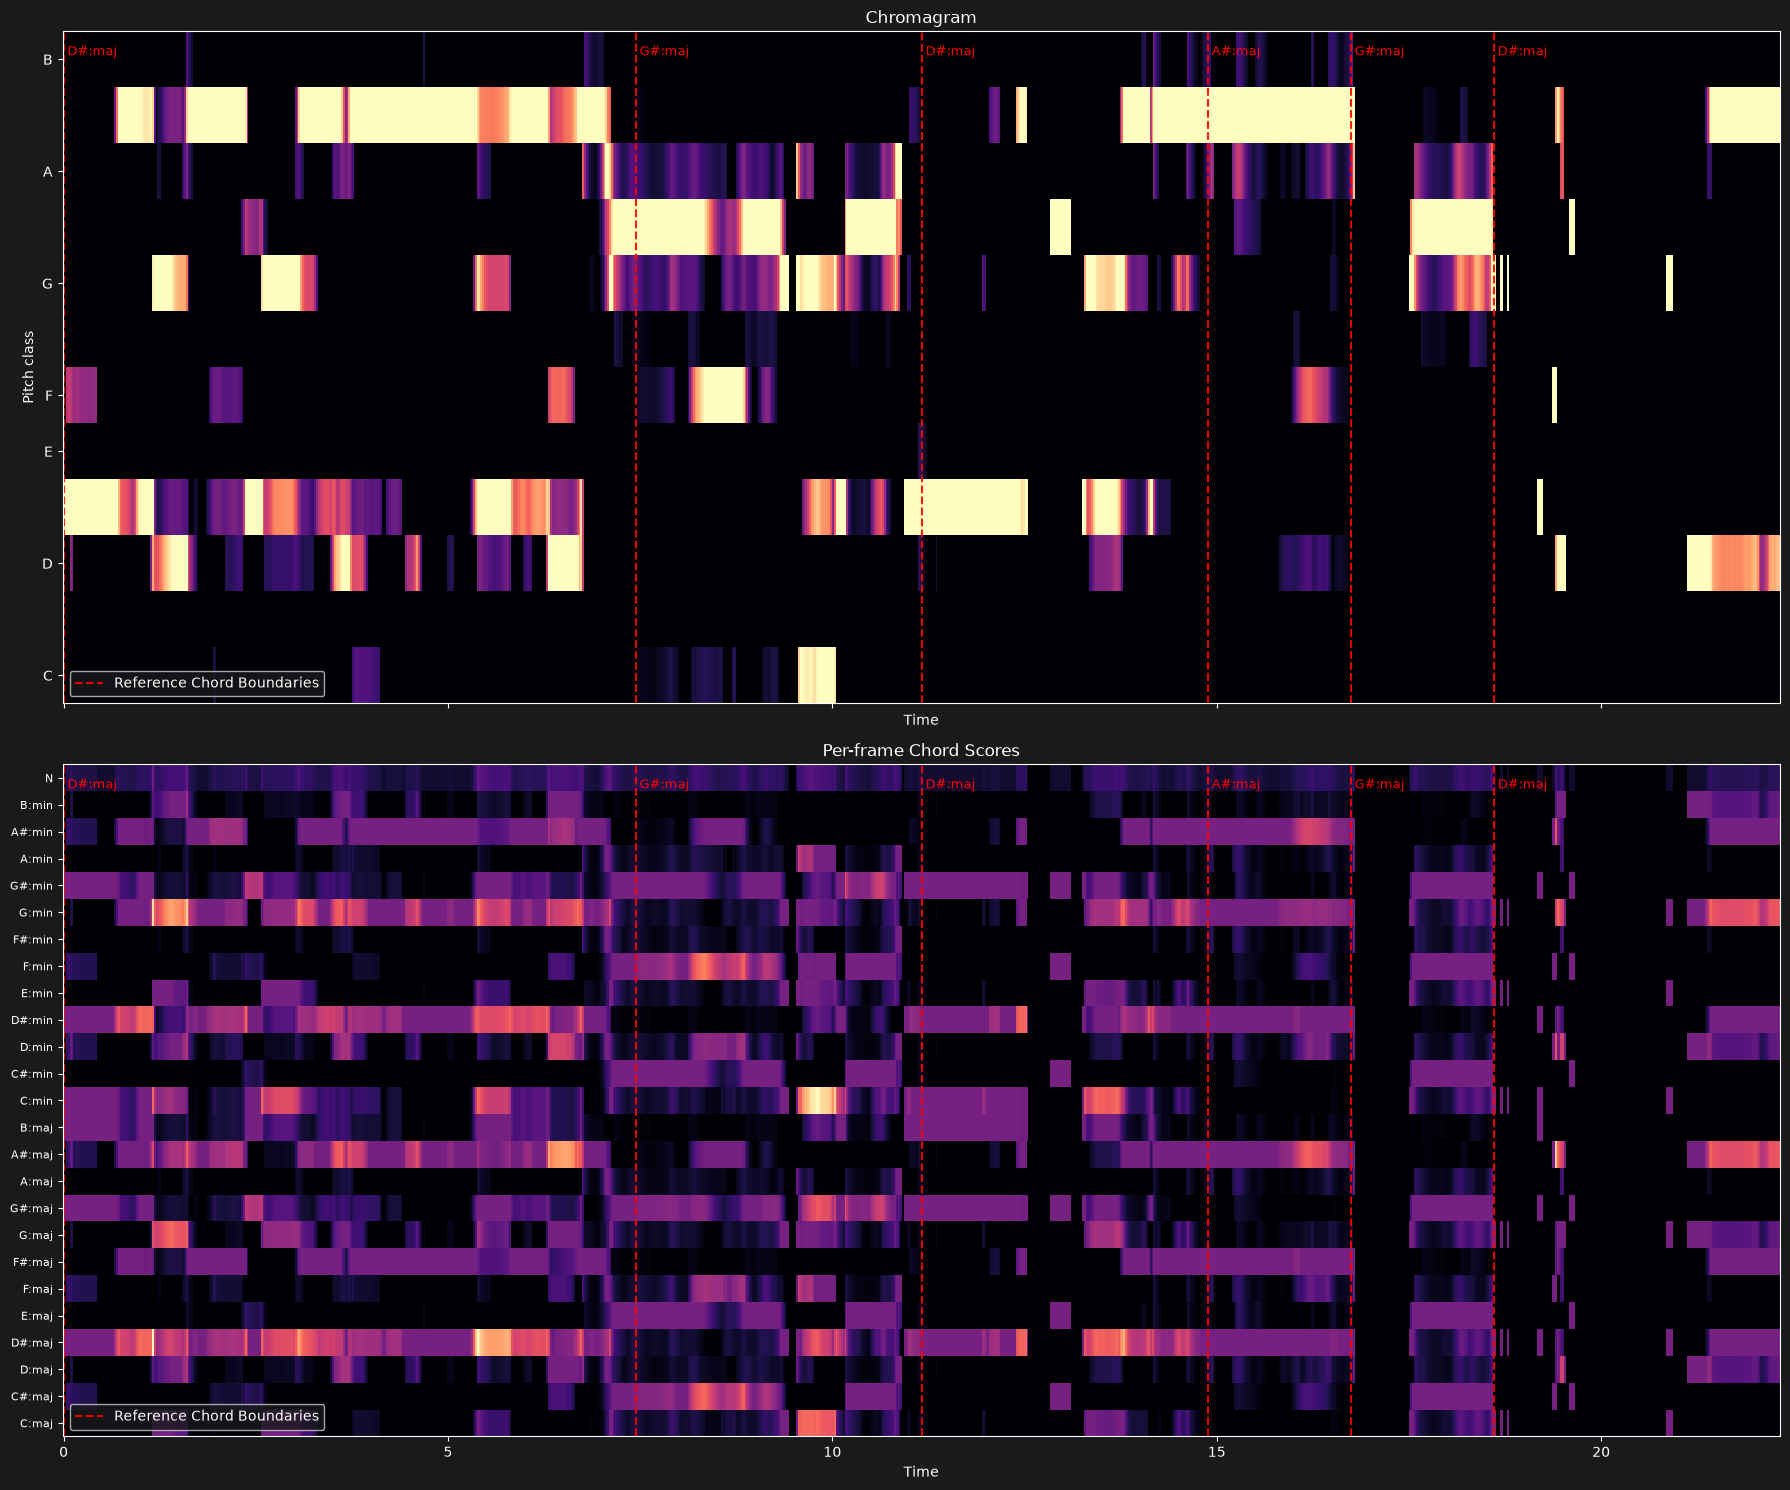

In [227]:
ref_times  = ref_combined[:, 0].astype(float)
ref_ends   = ref_combined[:, 1].astype(float)
ref_labels = ref_combined[:, 2].astype(str)


fix, ax = plt.subplots(nrows=2, figsize=(18,15), sharex=True)

librosa.display.specshow(chroma, sr=sr, hop_length=512, x_axis='time', y_axis='chroma', ax=ax[0])
librosa.display.specshow(scores, sr=sr, hop_length=512, x_axis='time', ax=ax[1])
ax[0].set_title('Chromagram')
ax[1].set_title('Per-frame Chord Scores')

for i in range(len(ax)):
    ax[i].vlines(
        ref_times,
        ymin=0, ymax=1,
        transform=ax[i].get_xaxis_transform(),
        color='red', ls="--", alpha=0.9,
        label="Reference Chord Boundaries"
    )
    ax[i].legend(loc="lower left")

    for t, lab in zip(ref_times, ref_labels):
        ax[i].text(
            t+.05, 0.96, lab,
            transform=ax[i].get_xaxis_transform(),
            rotation=0, ha='left', va='bottom',
            color='red', fontsize=9
        )

ax[1].set_yticks(np.arange(len(labels)))
ax[1].set_yticklabels(labels, fontsize=8)


plt.tight_layout()
plt.show()

In [228]:
# Run Viterbi algo
posteriors = np.exp(scores)
posteriors /= posteriors.sum(axis=0, keepdims=True)


In [330]:
# Compute independent frame-wise estimates
framewise_chord = np.argmax(posteriors, axis=0)

# And viterbi estimates
chords_vit = librosa.sequence.viterbi_discriminative(posteriors, trans)

In [ ]:
# Plot the results
fig, ax = plt.subplots(figsize=(16,7))
img = librosa.display.specshow(posteriors, x_axis="time", ax=ax, div_thresh=1./25)
hl = librosa.display.highlight(ax=ax, alpha=0.1)
fig.colorbar(img, ax=ax, label='Frame-wise Class Probability')
times = librosa.times_like(chords_vit)

ax.scatter(times, chords_ind + 0.25, alpha=0.85, marker='x', color='k',
           s=15, label='Independent', path_effects=hl)

ax.scatter(times, chords_vit - 0.25, alpha=0.85, marker='o', color='g',
           s=15, label='Viterbi', path_effects=hl)

ax.set(yticks=np.unique(chords_vit),
       yticklabels=[labels[i] for i in np.unique(chords_vit)])

ax.legend(loc='upper right', ncols=2)
plt.show()

In [332]:
# Sanity check with p_self equal to all other transitions probabilites - Should print true
trans_equal = librosa.sequence.transition_loop(25, 1/25)
np.array_equal(librosa.sequence.viterbi_discriminative(posteriors, trans_equal), framewise_chord)

True

In [329]:
# Calculate ref chord label  per frame
frame_to_times = librosa.frames_to_time(np.arange(chroma.shape[1]), sr=22050, hop_length=512)

starts = ref_combined[:,0].astype(float)
ends = ref_combined[:,1].astype(float)

# 4. Use broadcasting to find where values fall between starts and ends
# This creates a 2D boolean grid mapping every value to every interval

is_after_start = frame_to_times[:, np.newaxis] >= starts
is_before_end = frame_to_times[:, np.newaxis] < ends
matches = is_after_start & is_before_end

# extract matching row indices from frame_to_times for each value in ref_combined
row_indices = np.argmax(matches, axis=1)

label_per_frame = ref_combined[:,2][row_indices]
labelIdx_per_frame = np.where(labels_array == label_per_frame[:, None])[1]

# Try different p_self values
for p in [Fraction(1,25), .5, .9, .99, .992, .994, .995, .997, .999]:
    print(f"\n==== p: {p} =====")
    trans_p = librosa.sequence.transition_loop(25, p)
    vit = librosa.sequence.viterbi_discriminative(posteriors, trans_p)
    chord_cpm = round(float(np.count_nonzero(np.diff(vit)) / (duration / 60)), 2)
    print(f"Viterbi Chord change per minute: {chord_cpm}")

    # Calculate frame accuracy
    correct_frames = int((label_per_frame == labels_array[vit]).sum())
    print(f"Frame accuracy: {correct_frames/len(vit)*100:.2f}%")

print(f"\n=== Framewise ===")
print(f"Framewise chord change per minute: {round(float(np.count_nonzero(np.diff(framewise_chord)) / (duration / 60)), 2)}")
correct_frames = int((label_per_frame == labels_array[framewise_chord]).sum())
print(f"Frame accuracy: {correct_frames/len(framewise_chord)*100:.2f}%")


==== p: 1/25 =====
Viterbi Chord change per minute: 155.88
Frame accuracy: 43.24%

==== p: 0.5 =====
Viterbi Chord change per minute: 37.63
Frame accuracy: 42.62%

==== p: 0.9 =====
Viterbi Chord change per minute: 26.88
Frame accuracy: 42.41%

==== p: 0.99 =====
Viterbi Chord change per minute: 21.5
Frame accuracy: 44.91%

==== p: 0.992 =====
Viterbi Chord change per minute: 21.5
Frame accuracy: 44.91%

==== p: 0.994 =====
Viterbi Chord change per minute: 21.5
Frame accuracy: 44.91%

==== p: 0.995 =====
Viterbi Chord change per minute: 21.5
Frame accuracy: 44.91%

==== p: 0.997 =====
Viterbi Chord change per minute: 21.5
Frame accuracy: 44.91%

==== p: 0.999 =====
Viterbi Chord change per minute: 21.5
Frame accuracy: 44.91%

=== Framewise ===
Framewise chord change per minute: 155.88
Frame accuracy: 43.24%


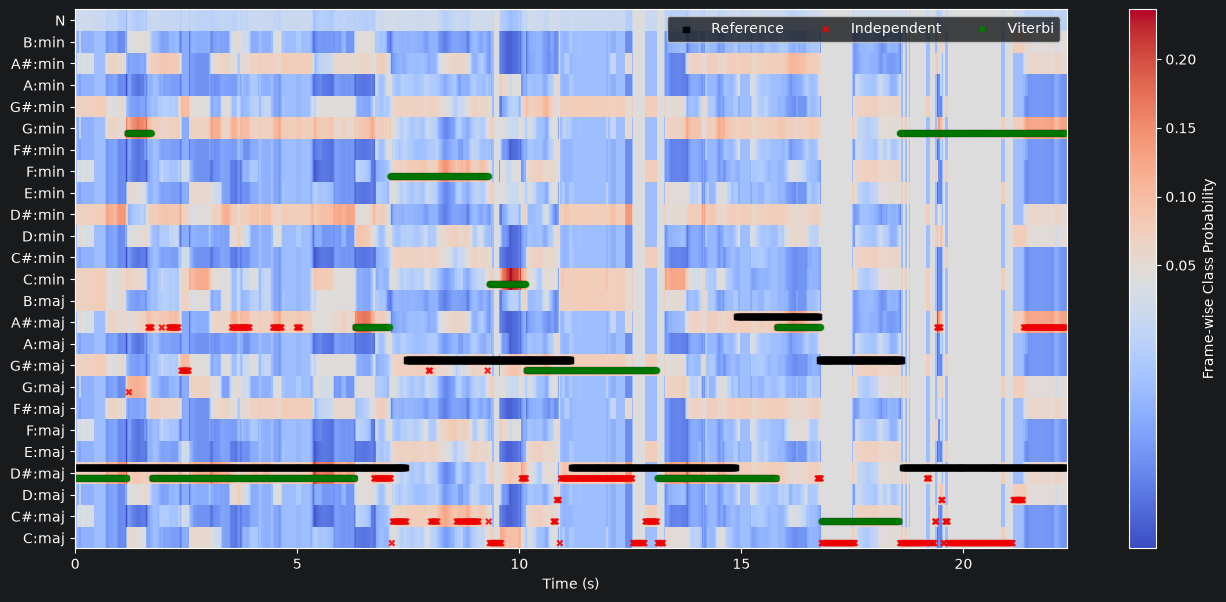

In [339]:
# Plot the results
fig, ax = plt.subplots(figsize=(16,7))
img = librosa.display.specshow(posteriors, x_axis="time", ax=ax, div_thresh=1./25)
hl = librosa.display.highlight(ax=ax, alpha=0.1)
fig.colorbar(img, ax=ax, label='Frame-wise Class Probability')
ax.set_xlabel("Time (s)")

times = librosa.times_like(chords_vit)

ax.scatter(times, labelIdx_per_frame + 0.25, alpha=0.85, marker='s', color='k',
           s=15, label='Reference', path_effects=hl)

ax.scatter(times, framewise_chord - 0.25, alpha=0.85, marker='x', color='r',
           s=15, label='Independent', path_effects=hl)

ax.scatter(times, chords_vit - 0.25, alpha=0.85, marker='o', color='g',
           s=15, label='Viterbi', path_effects=hl)

ax.set(yticks=range(25),
       yticklabels=labels)

ax.legend(loc='upper right', ncols=3)
plt.show()

The plot works and explains most of the 45%. In the two biggest wrong sections, Viterbi picked the triad that matches the notes actually played. The lead sheet names a different chord there.

7.4–10.2 s: F:min and C:min where the reference is G#:maj. The performed chord is G#:maj6(*5), so the notes are G#, C and F, with no D#. F minor is F, G#(Ab) and C, the same three notes. A maj6 chord without its fifth is the relative minor triad in another inversion. From chroma alone, F:min is the correct reading of that sound.

18.6–22.3 s: G:min where the reference is D#:maj. The performed chord is D#:maj7: D#, G, A# and D. G minor is G, A# and D, the top three notes of that chord. On top of that, 19–21 s is the grey, nearly silent stretch where the posteriors are flat. With no evidence to switch, Viterbi keeps G:min until the end.

Timing:

The change to G#:maj arrives about 2.7 s late, at 10.2 s instead of 7.44 s. That’s mostly the maj6 problem above, not lag.
D#:maj runs about 1 s past the A#:maj change at 14.88 s. That’s either the old chord ringing over or a real delay in the evidence.
The short A#:maj at 6.3–7.1 s comes before any A# in the reference. It may be a passing chord in the strumming.

16.8–18.6 s: C#:maj where the reference is G#:maj. The performed chord is G#:maj6(2,b5,*5): G#, C, F, A# and D. C#:maj shares F and G#. With five notes and no clear triad, the templates have little to work with.

Takeaway for V0: a large part of the error is not the decoder failing but the 25-triad vocabulary being unable to name these voicings. Per-frame scores pick the closest triad and Viterbi holds it. Even the performed labels wouldn’t fix this, because mir_eval reduces maj6 to maj and maj7 to maj, so F:min and G:min would still count as wrong.